# SUNSHIELD — BiLSTM Notebook 4: Evaluation & Final Files

**Place in Dr. Mai's workflow:** the last boxes of both drawings, for the BiLSTM.

```
TRAINING:  Actual 0/1 ─┐
                       ├─► F1 for each k (+ confusion matrix) ─► Best k
        Predicted 0/1 ─┘

TESTING:   Actual 0/1 ─┐   (using the best k from training only)
                       ├─► F1 + confusion matrix ─► final test result
        Predicted 0/1 ─┘
```

The **actual** 0/1 is the reference; the **predicted** 0/1 is what the BiLSTM's line says.

| | Predicted 1 | Predicted 0 |
|---|---|---|
| **Actual 1** | TP — anomaly found | FN — anomaly missed |
| **Actual 0** | FP — false alarm | TN — normal, correctly normal |

| Step | What happens | Output |
|---|---|---|
| 1 | Training: for each k → TP, FP, FN, TN, precision, recall, F1 | `metrics_all_k.csv` |
| 2 | Training: confusion matrix for each k | `confusion_matrices_train.png` |
| 3 | Choose the best k = highest training F1 | `best_k.txt` |
| 4 | Validation: metrics + confusion matrix using the best k | validation results |
| 5 | Testing: metrics + confusion matrix using the best k from training | test results |
| 6 | Plot precision / recall / F1 vs k | `metrics_vs_k.png` |
| 7 | Actual vs predicted plot for each split, red dots on anomalies | `actual_vs_predicted_*.png` |
| 8 | File 4: Validation Thresholding | `4_BiLSTM_Validation_Output_Thresholding.csv` |
| 9 | File 6: Testing Anomaly | `6_BiLSTM_Testing_Output_Anomaly.csv` |
| 10 | Zip and download all final files and plots | `bilstm_final_outputs.zip` |

## Settings

In [1]:
import os, shutil, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

MODEL_NAME = 'BiLSTM'
INVERTER = 'LlT2YUhhzqhg5Sw'   # inverter of the actual-vs-predicted plots, the same one as the LSTM plots
                               # (None = the inverter with the most actual anomalies in the test split)
SPLITS = ['train', 'val', 'test']
SPLIT_NAMES = {'train': 'Training', 'val': 'Validation', 'test': 'Testing'}
OUT_DIR = 'bilstm_final_outputs'
os.makedirs(OUT_DIR, exist_ok=True)

# Chart style: actual = blue, predicted = orange, anomalies = red (same in every plot)
SURFACE, INK, INK_2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'
BLUE, ORANGE, AQUA, RED = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
BLUES = LinearSegmentedColormap.from_list('blues', ['#cde2fb', '#86b6ef', '#2a78d6', '#184f95', '#0d366b'])
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'axes.edgecolor': GRID,
                     'axes.labelcolor': INK_2, 'xtick.color': INK_2, 'ytick.color': INK_2,
                     'axes.titlecolor': INK, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
                     'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 2,
                     'legend.frameon': False, 'font.size': 10})
figures = {}        # every saved plot, checked before the zip

## Upload BiLSTM Notebook 3 outputs

Run the cell below, click **Choose Files** and select `bilstm_step3_outputs.zip`.

In [2]:
from google.colab import files
uploaded = files.upload()
shutil.unpack_archive(list(uploaded)[0], 'bilstm_step3_outputs', 'zip')

anomalies = {s: pd.read_csv(f'bilstm_step3_outputs/anomaly_{s}.csv', parse_dates=['DATE_TIME']) for s in SPLITS}
with open('bilstm_step3_outputs/settings.txt') as f:
    settings = dict(line.strip().split(' = ', 1) for line in f if ' = ' in line)
K_VALUES = [float(k) for k in settings['K_VALUES'].strip('[]').split(',')]
print('Notebook 3 settings:', settings)
for s in SPLITS:
    print(f'{s:5s}: {len(anomalies[s]):,} readings')

Notebook 3 settings: {'MODEL': 'BiLSTM', 'MODE': 'level', 'PRUNING': 'False', 'K_VALUES': '[1, 1.5, 2, 2.5, 3]', 'MIN_HISTORY': '2'}
train: 41,937 readings
val  : 11,968 readings
test : 11,110 readings


## Helper functions

`evaluate` counts the 4 cases and computes the metrics:

$$\text{Precision} = \frac{TP}{TP + FP} \qquad \text{Recall} = \frac{TP}{TP + FN} \qquad
F1 = \frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

If a denominator is 0 (for example no reading flagged at all) the metric is set to 0.
`plot_confusion` draws one confusion matrix: rows = actual line, columns = predicted line.

In [3]:
def evaluate(df, k):
    actual = df[f'actual_anomaly_k{k:g}'].to_numpy()
    predicted = df[f'predicted_anomaly_k{k:g}'].to_numpy()
    tp = int(((actual == 1) & (predicted == 1)).sum())
    fp = int(((actual == 0) & (predicted == 1)).sum())
    fn = int(((actual == 1) & (predicted == 0)).sum())
    tn = int(((actual == 0) & (predicted == 0)).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {'k': k, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
            'precision': precision, 'recall': recall, 'F1': f1}

def plot_confusion(ax, row, title):
    matrix = np.array([[row['TP'], row['FN']], [row['FP'], row['TN']]], dtype=int)
    ax.imshow(matrix, cmap=BLUES, vmin=0, vmax=matrix.max())
    ax.grid(False)
    for (i, j), value in np.ndenumerate(matrix):
        name = [['TP', 'FN'], ['FP', 'TN']][i][j]
        ax.text(j, i, f'{name}\n{value:,}', ha='center', va='center', fontsize=10,
                color=SURFACE if value > matrix.max() / 2 else INK)
    ax.set_xticks([0, 1], ['Anomaly (1)', 'Normal (0)'])
    ax.set_yticks([0, 1], ['Anomaly (1)', 'Normal (0)'])
    ax.set_xlabel('Predicted line')
    ax.set_ylabel('Actual line')
    ax.set_title(title, loc='left', fontsize=10)

## Step 1 — Training: TP, FP, FN, TN, precision, recall and F1 for each k

In [4]:
train_metrics = pd.DataFrame([evaluate(anomalies['train'], k) for k in K_VALUES]).set_index('k')
train_metrics.to_csv(os.path.join(OUT_DIR, 'metrics_all_k.csv'))
train_metrics.round(4)

,TP,FP,FN,TN,precision,recall,F1
k,,,,,,,
1.0,12954,4334,5601,19048,0.7493,0.6981,0.7228
1.5,1860,2646,2627,34804,0.4128,0.4145,0.4137
2.0,226,295,566,40850,0.4338,0.2854,0.3442
2.5,23,130,73,41711,0.1503,0.2396,0.1847
3.0,21,66,44,41806,0.2414,0.3231,0.2763


## Step 2 — Training: confusion matrix for each k

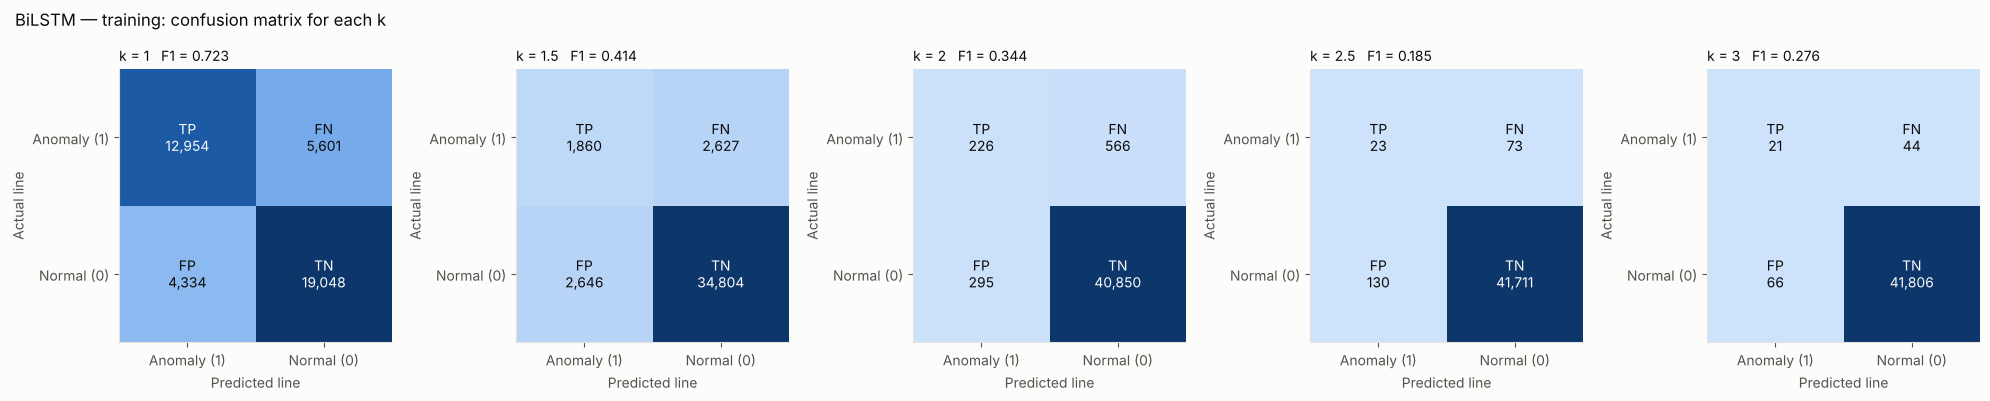

In [5]:
fig, axes = plt.subplots(1, len(K_VALUES), figsize=(4 * len(K_VALUES), 4))
for ax, k in zip(axes, K_VALUES):
    plot_confusion(ax, train_metrics.loc[k], f'k = {k:g}   F1 = {train_metrics.loc[k, "F1"]:.3f}')
fig.suptitle(f'{MODEL_NAME} — training: confusion matrix for each k', x=0.01, ha='left', color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, 'confusion_matrices_train.png'), dpi=150)
plt.show()

## Step 3 — Choose the best k = highest training F1

Only the **training** results are used; validation and test are not looked at when choosing k.
If two k values had exactly the same F1, the smaller k would be kept.

In [6]:
best_k = float(train_metrics['F1'].idxmax())
with open(os.path.join(OUT_DIR, 'best_k.txt'), 'w') as f:
    f.write(f'model = {MODEL_NAME}\nbest_k = {best_k:g}\ntraining F1 = {train_metrics.loc[best_k, "F1"]:.4f}\n')
print(f'{MODEL_NAME}: best k = {best_k:g}  (training F1 = {train_metrics.loc[best_k, "F1"]:.4f})')

BiLSTM: best k = 1  (training F1 = 0.7228)


## Steps 4 and 5 — Validation and testing with the best k from training

The best k is used as it is — nothing is tuned on validation or test. The test result is the **final result**.

In [7]:
results = pd.DataFrame([{'split': s, **evaluate(anomalies[s], best_k)} for s in SPLITS]).set_index('split')
results.to_csv(os.path.join(OUT_DIR, 'results_best_k.csv'))
print(f'{MODEL_NAME} results with the best k = {best_k:g}:')
results.round(4)

BiLSTM results with the best k = 1:


,k,TP,FP,FN,TN,precision,recall,F1
split,,,,,,,,
train,1.0,12954,4334,5601,19048,0.7493,0.6981,0.7228
val,1.0,3574,1112,833,6449,0.7627,0.8110,0.7861
test,1.0,3504,1138,1119,5349,0.7548,0.7579,0.7564


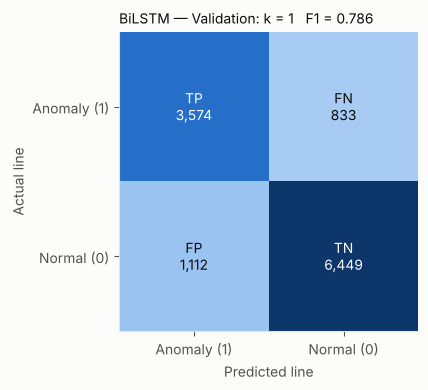

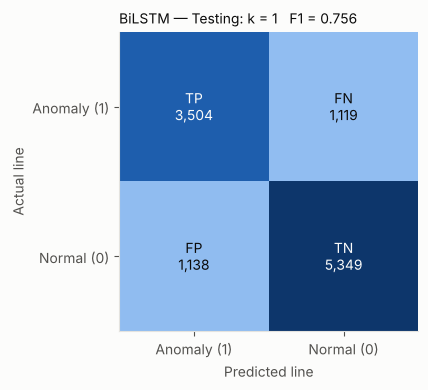

In [8]:
for split in ['val', 'test']:
    fig, ax = plt.subplots(figsize=(4.5, 4))
    plot_confusion(ax, results.loc[split],
                   f'{MODEL_NAME} — {SPLIT_NAMES[split]}: k = {best_k:g}   F1 = {results.loc[split, "F1"]:.3f}')
    fig.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, f'confusion_matrix_{split}.png'), dpi=150)
    plt.show()

## Step 6 — Precision, recall and F1 vs k (training)

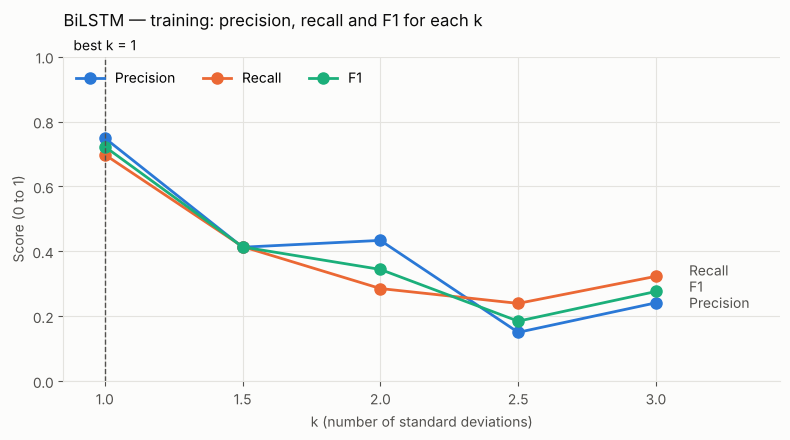

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
series = [('precision', 'Precision', BLUE), ('recall', 'Recall', ORANGE), ('F1', 'F1', AQUA)]
for column, label, color in series:
    ax.plot(K_VALUES, train_metrics[column], color=color, marker='o', markersize=8, label=label)

# Direct labels at the right end, pushed apart so they never overlap
ends = sorted(((train_metrics[c].iloc[-1], l) for c, l, _ in series), key=lambda e: e[0])
min_gap, placed = 0.05, []
for y, label in ends:
    y_label = max(y, placed[-1] + min_gap) if placed else y
    placed.append(y_label)
    ax.annotate(label, (K_VALUES[-1], y), xytext=(K_VALUES[-1] + 0.12, y_label), color=INK_2, va='center')

ax.axvline(best_k, color=INK_2, linestyle='--', linewidth=1)
ax.annotate(f'best k = {best_k:g}', (best_k, 1.02), xycoords=('data', 'axes fraction'), ha='center', color=INK)
ax.set_xticks(K_VALUES)
ax.set_xlim(K_VALUES[0] - 0.15, K_VALUES[-1] + 0.45)
ax.set_ylim(0, 1)
ax.set_xlabel('k (number of standard deviations)')
ax.set_ylabel('Score (0 to 1)')
ax.set_title(f'{MODEL_NAME} — training: precision, recall and F1 for each k', loc='left', pad=22)
ax.legend(loc='upper left', ncol=3)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, 'metrics_vs_k.png'), dpi=150)
figures['metrics_vs_k.png'] = fig
plt.show()

## Step 7 — Actual vs predicted for each split, red dots on anomalies

One inverter (`INVERTER`) for the whole split, anomalies with the **best k**:
- **red dot** on the actual line = the actual line is an anomaly at that reading
- **red ring** on the predicted line = the predicted line is an anomaly at that reading

Night readings were removed in LSTM Notebook 1, so each night appears as a straight line between evening and morning.

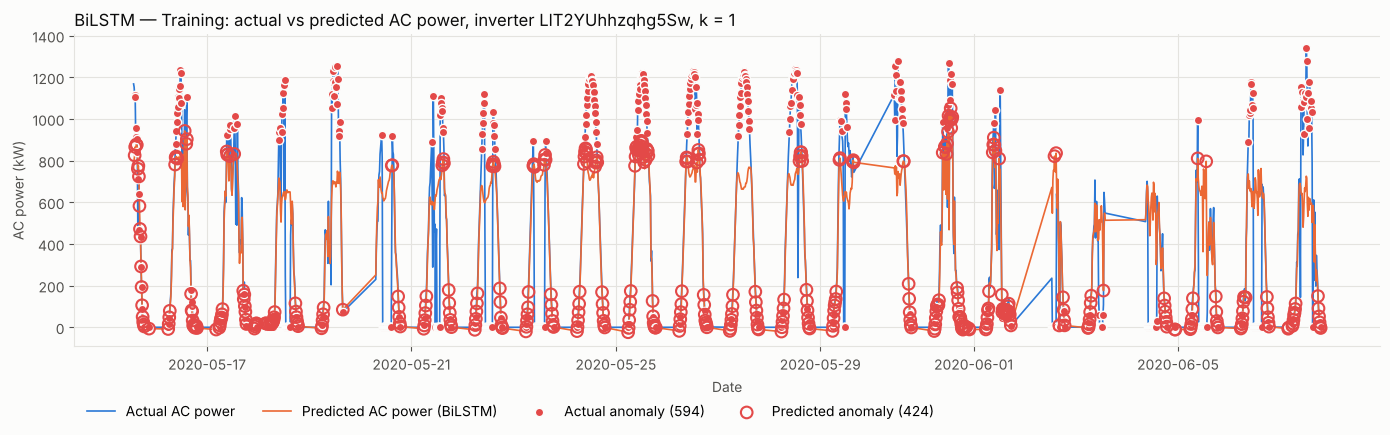

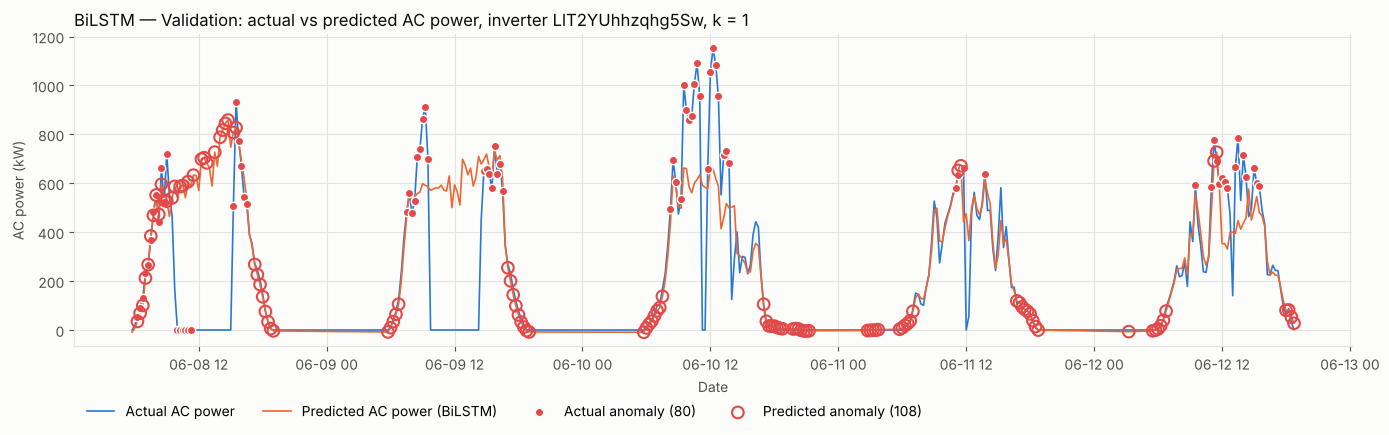

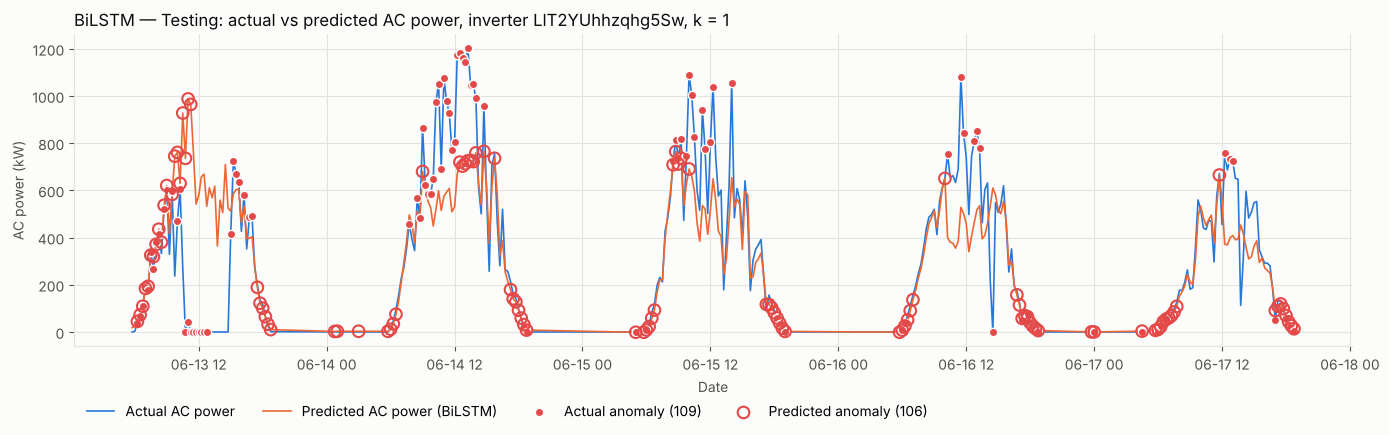

In [10]:
actual_col, predicted_col = f'actual_anomaly_k{best_k:g}', f'predicted_anomaly_k{best_k:g}'
if INVERTER is None:
    INVERTER = anomalies['test'].groupby('SOURCE_KEY')[actual_col].sum().idxmax()

for split in SPLITS:
    d = anomalies[split]
    d = d[d['SOURCE_KEY'] == INVERTER].sort_values('DATE_TIME')
    fig, ax = plt.subplots(figsize=(14, 4.5))
    ax.plot(d['DATE_TIME'], d['ACTUAL_AC_POWER_kW'], color=BLUE, linewidth=1.2, label='Actual AC power')
    ax.plot(d['DATE_TIME'], d['PREDICTED_AC_POWER_kW'], color=ORANGE, linewidth=1.2,
            label=f'Predicted AC power ({MODEL_NAME})')
    a, p = d[d[actual_col] == 1], d[d[predicted_col] == 1]
    ax.scatter(a['DATE_TIME'], a['ACTUAL_AC_POWER_kW'], s=36, color=RED, zorder=3,
               edgecolors=SURFACE, linewidths=1, label=f'Actual anomaly ({len(a)})')
    ax.scatter(p['DATE_TIME'], p['PREDICTED_AC_POWER_kW'], s=70, facecolors='none', edgecolors=RED,
               linewidths=1.5, zorder=3, label=f'Predicted anomaly ({len(p)})')
    ax.set_title(f'{MODEL_NAME} — {SPLIT_NAMES[split]}: actual vs predicted AC power, inverter {INVERTER}, '
                 f'k = {best_k:g}', loc='left')
    ax.set_xlabel('Date')
    ax.set_ylabel('AC power (kW)')
    ax.legend(loc='upper left', ncol=4, bbox_to_anchor=(0, -0.14))
    fig.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, f'actual_vs_predicted_{split}.png'), dpi=150)
    figures[f'actual_vs_predicted_{split}.png'] = fig
    plt.show()

## Steps 8 and 9 — Files 4 and 6 (and the full set of 6 files)

| File | Split | Columns |
|---|---|---|
| 4 Validation Thresholding | val | inverter, time, `K`, actual 0/1, predicted 0/1 with the **best k**, `RESULT` (TP/FP/FN/TN) |
| 6 Testing Anomaly | test | inverter, time, actual and predicted kW, `K`, actual 0/1, predicted 0/1, `RESULT` |

So that `bilstm_final_outputs.zip` holds all 6 files, Files 1, 3, 5 are written again from the same readings
(identical to the ones of Notebook 2) and File 2 is copied from Notebook 3.

In [11]:
ID = ['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME']
KW = ['ACTUAL_AC_POWER_kW', 'PREDICTED_AC_POWER_kW']

def with_best_k(df, keep_kw=False):
    out = df[ID + (KW if keep_kw else [])].copy()
    out['K'] = best_k
    out['ACTUAL_ANOMALY'] = df[actual_col]
    out['PREDICTED_ANOMALY'] = df[predicted_col]
    out['RESULT'] = np.select(
        [(out.ACTUAL_ANOMALY == 1) & (out.PREDICTED_ANOMALY == 1), (out.ACTUAL_ANOMALY == 0) & (out.PREDICTED_ANOMALY == 1),
         (out.ACTUAL_ANOMALY == 1) & (out.PREDICTED_ANOMALY == 0)], ['TP', 'FP', 'FN'], default='TN')
    return out

final_files = {
    f'1_{MODEL_NAME}_Training_Output_Prediction.csv':     anomalies['train'][ID + KW],
    f'3_{MODEL_NAME}_Validation_Output_Prediction.csv':   anomalies['val'][ID + KW],
    f'4_{MODEL_NAME}_Validation_Output_Thresholding.csv': with_best_k(anomalies['val']),
    f'5_{MODEL_NAME}_Testing_Output_Prediction.csv':      anomalies['test'][ID + KW],
    f'6_{MODEL_NAME}_Testing_Output_Anomaly.csv':         with_best_k(anomalies['test'], keep_kw=True),
}
for name, df in final_files.items():
    df.to_csv(os.path.join(OUT_DIR, name), index=False)
file2 = glob.glob(f'{MODEL_NAME.lower()}_step3_outputs/2_*_Training_Output_Thresholding.csv')[0]
shutil.copy(file2, OUT_DIR)
shutil.copy(f'{MODEL_NAME.lower()}_step3_outputs/sigma_bands.png', OUT_DIR)

for name in sorted(f for f in os.listdir(OUT_DIR) if f[0].isdigit()):
    df = pd.read_csv(os.path.join(OUT_DIR, name))
    print(f'{name:48s} {len(df):7,} rows  {df.shape[1]:2d} columns')

# The RESULT column must give the same counts as Step 5
test_counts = final_files[f'6_{MODEL_NAME}_Testing_Output_Anomaly.csv']['RESULT'].value_counts()
assert all(test_counts.get(c, 0) == results.loc['test', c] for c in ['TP', 'FP', 'FN', 'TN'])
print('\nTesting counts match Step 5:', test_counts.to_dict())
final_files[f'6_{MODEL_NAME}_Testing_Output_Anomaly.csv'].head()

1_BiLSTM_Training_Output_Prediction.csv           41,937 rows   5 columns
2_BiLSTM_Training_Output_Thresholding.csv         41,937 rows  13 columns
3_BiLSTM_Validation_Output_Prediction.csv         11,968 rows   5 columns
4_BiLSTM_Validation_Output_Thresholding.csv       11,968 rows   7 columns
5_BiLSTM_Testing_Output_Prediction.csv            11,110 rows   5 columns
6_BiLSTM_Testing_Output_Anomaly.csv               11,110 rows   9 columns

Testing counts match Step 5: {'TN': 5349, 'TP': 3504, 'FP': 1138, 'FN': 1119}


,PLANT_ID,SOURCE_KEY,DATE_TIME,ACTUAL_AC_POWER_kW,PREDICTED_AC_POWER_kW,K,ACTUAL_ANOMALY,PREDICTED_ANOMALY,RESULT
0,4135001,1BY6WEcLGh8j5v7,2020-06-13 05:45:00,0.000000,6.398285,1.0,0,0,TN
1,4135001,1BY6WEcLGh8j5v7,2020-06-13 06:00:00,9.162500,16.761902,1.0,0,0,TN
2,4135001,1BY6WEcLGh8j5v7,2020-06-13 06:15:00,33.228571,36.790620,1.0,1,1,TP
3,4135001,1BY6WEcLGh8j5v7,2020-06-13 06:30:00,55.037500,59.196228,1.0,1,1,TP
4,4135001,1BY6WEcLGh8j5v7,2020-06-13 06:45:00,102.142857,97.034546,1.0,1,1,TP


## Check every plot: title, axis names with units, legend

The confusion matrices have no legend by nature (each cell is labelled), so they are checked for title and axis names only.

In [12]:
rows = []
for name, fig in figures.items():
    ax = fig.axes[0]
    rows.append({'plot': name, 'title': bool(ax.get_title(loc='left')),
                 'x axis name': ax.get_xlabel(), 'y axis name': ax.get_ylabel(),
                 'units in y axis': ('(kW' in ax.get_ylabel()) or ('Score' in ax.get_ylabel()),
                 'legend': ax.get_legend() is not None})
check = pd.DataFrame(rows).set_index('plot')
assert check[['title', 'units in y axis', 'legend']].all().all()
print('All plots have a title, named axes with units, and a legend.')
check

All plots have a title, named axes with units, and a legend.


,title,x axis name,y axis name,units in y axis,legend
plot,,,,,
metrics_vs_k.png,True,k (number of standard deviations),Score (0 to 1),True,True
actual_vs_predicted_train.png,True,Date,AC power (kW),True,True
actual_vs_predicted_val.png,True,Date,AC power (kW),True,True
actual_vs_predicted_test.png,True,Date,AC power (kW),True,True


## Step 10 — Zip and download all final files and plots

`bilstm_final_outputs.zip` holds the 6 files, the plots of this notebook, `sigma_bands.png` from Notebook 3, and the
metrics (`metrics_all_k.csv`, `results_best_k.csv`, `best_k.txt`).

In [13]:
shutil.make_archive('bilstm_final_outputs', 'zip', OUT_DIR)
for f in sorted(os.listdir(OUT_DIR)):
    print(f'{f:48s} {os.path.getsize(os.path.join(OUT_DIR, f)) / 1e6:6.2f} MB')

files.download('bilstm_final_outputs.zip')

1_BiLSTM_Training_Output_Prediction.csv            2.74 MB
2_BiLSTM_Training_Output_Thresholding.csv          2.68 MB
3_BiLSTM_Validation_Output_Prediction.csv          0.78 MB
4_BiLSTM_Validation_Output_Thresholding.csv        0.66 MB
5_BiLSTM_Testing_Output_Prediction.csv             0.73 MB
6_BiLSTM_Testing_Output_Anomaly.csv                0.85 MB
actual_vs_predicted_test.png                       0.24 MB
actual_vs_predicted_train.png                      0.35 MB
actual_vs_predicted_val.png                        0.22 MB
best_k.txt                                         0.00 MB
confusion_matrices_train.png                       0.11 MB
confusion_matrix_test.png                          0.03 MB
confusion_matrix_val.png                           0.03 MB
metrics_all_k.csv                                  0.00 MB
metrics_vs_k.png                                   0.08 MB
results_best_k.csv                                 0.00 MB
sigma_bands.png                                    0.19 